In [2]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT =Path.cwd().parent if Path.cwd().name== "notebooks" else Path.cwd()
DATA_FILE =PROJECT_ROOT /"data" /"raw" / "FinancialPhraseBank-v1.0" /"Sentences_75Agree.txt"

print("Project root:", PROJECT_ROOT)
print("Data file exists:", DATA_FILE.exists())

Project root: h:\Desktop\financial-news-intelligence
Data file exists: True


In [3]:
raw_bytes = DATA_FILE.read_bytes()

try:
    raw_bytes.decode("utf-8")
    print("UTF-8 decoding worked.")
except UnicodeDecodeError as error:
    print("UTF-8 decoding FAILED:")
    print(error)

UTF-8 decoding FAILED:
'utf-8' codec can't decode byte 0xf1 in position 1724: invalid continuation byte


In [25]:
def load_phrasebank(file_path):
    rows = []
    bad_lines = []  ##line we couldnt parse, we keep it so we can inspect them instead of silently dropping them

    with open(file_path, encoding="latin-1") as f:
        for line_number, line in enumerate(f, start=1):
            line = line.strip() ## remove the new line asn surrounding spaces
            if not line :
                continue
            if "@" not in line:                      ## no separator means we cant find the label
                bad_lines.append((line_number,line))
                continue
            sentence, label = line.rsplit("@", 1) ##split on the LAST "@" only
            rows.append({"sentence": sentence.strip(),"label":label.strip()})

    return pd.DataFrame(rows), bad_lines

df, bad_lines = load_phrasebank(DATA_FILE)

print("Rows loaded:", len(df))
print("Unparseable lines:" ,len(bad_lines))

Rows loaded: 3453
Unparseable lines: 0


In [26]:
###checking the labels, we expect exactly 3 clean values
print("Unique labels:", df["label"].unique())
print()

##data typr and missing values
df.info()
print()

##confirm the encoding fix worked on the name you found
print(df[df["sentence"].str.contains("Sepp")]["sentence"].tolist())

pd.set_option("display.max_colwidth",None)
df.head()

Unique labels: <StringArray>
['neutral', 'positive', 'negative']
Length: 3, dtype: str

<class 'pandas.DataFrame'>
RangeIndex: 3453 entries, 0 to 3452
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   sentence  3453 non-null   str  
 1   label     3453 non-null   str  
dtypes: str(2)
memory usage: 54.1 KB

["Clothing retail chain Sepp+ñl+ñ 's sales increased by 8 % to EUR 155.2 mn , and operating profit rose to EUR 31.1 mn from EUR 17.1 mn in 2004 .", "Seppala 's revenue increased by 0.2 % to EUR10 .1 m. In Finland , revenue went down by 2.4 % to EUR6 .8 m , while sales abroad rose by 6.2 % to EUR3 .3 m. Sales increased in all the Baltic countries as well as in Russia and Ukraine .", "Clothing chain Sepp+ñl+ñ 's net sales increased by 7.0 % to EUR 30.8 mn .", 'Seppala transferred the sale to a greater extent than last year to February , and this is reflected on the January sales figures .', "In the meantime the CEO 's duties 

,sentence,label
0,"According to Gran , the company has no plans to move all production to Russia , although that is where the company is growing .",neutral
1,With the new production plant the company would increase its capacity to meet the expected increase in demand and would improve the use of raw materials and therefore increase the production profitability .,positive
2,"For the last quarter of 2010 , Componenta 's net sales doubled to EUR131m from EUR76m for the same period a year earlier , while it moved to a zero pre-tax profit from a pre-tax loss of EUR7m .",positive
3,"In the third quarter of 2010 , net sales increased by 5.2 % to EUR 205.5 mn , and operating profit by 34.9 % to EUR 23.5 mn .",positive
4,Operating profit rose to EUR 13.1 mn from EUR 8.7 mn in the corresponding period in 2007 representing 7.7 % of net sales .,positive


In [12]:
import re
from collections import Counter

## any char outside ASCII is a candidate for corruption
non_ascii_mask = df["sentence"].str.contains(r"[^\x00-\x7F]",regex=True)
print("Sentence with non-ASCII characters:",non_ascii_mask.sum(),
f"({non_ascii_mask.mean()*100:.1f}% of the dataset)")
print()

## counting each non ascii char together with the character just before it,
# so we can see recurring patterns like "+ñ"

patterns = Counter()
for sentence in df.loc[non_ascii_mask, "sentence"]:
    for match in re.finditer(r".[^\x00-\x7F]", sentence):
        patterns[match.group()] += 1

print("Most common patterns:")
for pattern, count in patterns.most_common(15):
    print(f"{pattern!r}:{count}")
print()

##a  few full examples so we can see them in context
print("Examples:")
for sentence in df.loc[non_ascii_mask, "sentence"].head(8):
    print(" -",sentence)



Sentence with non-ASCII characters: 74 (2.1% of the dataset)

Most common patterns:
'+ñ':43
'+à':16
'+ó':9
'+Â':8
'+Ñ':6
'-¦':6
'-á':4
'+ä':4
'-¼':4
'+£':3
'-®':2
'-«':2
'+®':2
'-Á':2
'+é':2

Examples:
 - Clothing retail chain Sepp+ñl+ñ 's sales increased by 8 % to EUR 155.2 mn , and operating profit rose to EUR 31.1 mn from EUR 17.1 mn in 2004 .
 - Finnish Bank of +àland 's consolidated net operating profit increased from EUR 4.8 mn in the first quarter of 2005 to EUR 6.4 mn in the first quarter of 2006 .
 - Net sales of Finnish food industry company L+ñnnen Tehtaat 's continuing operations increased by 13 % in 2008 to EUR 349.1 mn from EUR 309.6 mn in 2007 .
 - Clothing chain Sepp+ñl+ñ 's net sales increased by 7.0 % to EUR 30.8 mn .
 - Finnish Bank of +àland reports its operating profit rose to EUR 21.3 mn in the second quarter of 2009 from EUR 6.1 mn in the corresponding period in 2008 .
 - According to HKScan Finland , the plan is to increase J+ñrvi-Suomen Portti 's net sales to E

          count  percent
label                   
neutral    2146     62.1
positive    887     25.7
negative    420     12.2

Total: 3453 | Percent total: 100.0


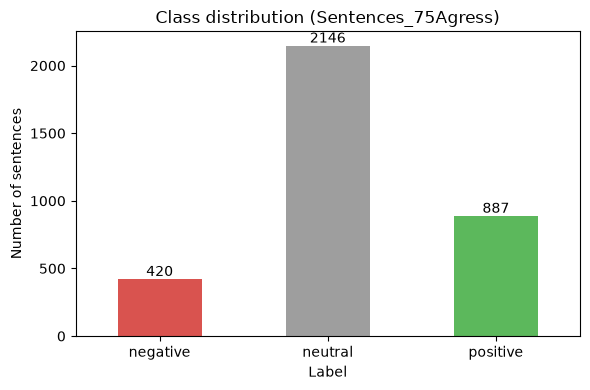

In [16]:
import matplotlib.pyplot as plt 

FIGURES_DIR = PROJECT_ROOT /"results" /"figures"

# counts and percentages per class
label_counts = df["label"].value_counts()
label_percent = df["label"].value_counts(normalize=True).mul(100).round(1)
distribution  = pd.DataFrame({"count": label_counts,"percent":label_percent})
print(distribution)
print()
print("Total:", distribution["count"].sum(),"| Percent total:", distribution["percent"].sum())

##bar chart, fixed class order so every plot in the project looks the same
class_order = ["negative","neutral","positive"]
ax = label_counts.reindex(class_order).plot(kind="bar", color=["#d9534f","#9e9e9e","#5cb85c"],
figsize=(6,4),rot=0)
ax.set_title("Class distribution (Sentences_75Agress)")
ax.set_xlabel("Label")
ax.set_ylabel("Number of sentences")
for i, count in enumerate(label_counts.reindex(class_order)):
    ax.text(i, count, str(count),ha="center",va="bottom")  ##write the count on top of each bar
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_class_distribution.png", dpi=150)
plt.show()

## Data quality log (Sentences_75Agree)

- **Encoding:** file is Latin-1, not UTF-8. Load with `encoding="latin-1"`.
- **Mojibake:** 74 sentences (2.1%) contain corrupted characters (e.g. `Sepp+ñl+ñ` = Seppälä). Mostly in proper names. Repair planned in Phase 3.
- **Inconsistent entity spelling:** `Sepp+ñl+ñ` vs `Seppala` for the same company.
- **Pre-tokenized text:** spaces before punctuation (`Finland , plans`).
- **Broken numbers:** decimals sometimes split (`EUR10 .1 m`).
- **Class imbalance:** neutral 62.1%, positive 25.7%, negative 12.2%.
- **Majority-class baseline:** accuracy 62.1%, Macro-F1 0.255.

In [18]:
##for exact duplicate
## keep=False marks every copy as a duplicate, not just the second one, so we can see full groups
exact_dup_mask= df.duplicated(subset="sentence",keep=False)

print("Rows involved in exact duplicates:", exact_dup_mask.sum())
print("Unique sentence that are duplicates:", df.loc[exact_dup_mask,"sentence"].nunique())
print("Extra copies (rows we could drop):", df.duplicated(subset="sentence").sum())

##do any duplicated sentence hv conflicting labels?
labels_per_sentence = (
    df[exact_dup_mask].groupby("sentence")["label"].nunique()
)
conflicting = labels_per_sentence[labels_per_sentence > 1]
print("Duplicated sentences with CONFLICTING labels", len(conflicting))
print()

#show the duplicate groups
print("Duplicate group:")
print(df[exact_dup_mask].sort_values("sentence").to_string())


Rows involved in exact duplicates: 10
Unique sentence that are duplicates: 5
Extra copies (rows we could drop): 5
Duplicated sentences with CONFLICTING labels 0

Duplicate group:
                                                                                                                                                                                                                                                                                                      sentence    label
1544                                                                                                                                                                                                                                                  Ahlstrom 's share is quoted on the NASDAQ OMX Helsinki .  neutral
1545                                                                                                                                                                                                 

In [22]:
## near duplicate
def normalize_for_dup_check(text):
    text = text.lower()
    text = re.sub(r"\d+(?:[.,]\d+)*","<num>",text)
    text = re.sub(r"\s"," ",text).strip()
    return text

df["dup_key"]=df["sentence"].apply(normalize_for_dup_check)

near_dup_mask = df.duplicated(subset="dup_key", keep= False)
print("Rows in near-duplicated group:" ,near_dup_mask.sum())
print("Number of near-suplicated groups:", df.loc[near_dup_mask,"dup_key"].nunique())
print()

## conflicting labels inside near-duplicaating groups
labels_per_key = df[near_dup_mask].groupby("dup_key")["label"].nunique()
print("Near-duplicate grooups with CONFLICTING labels:",(labels_per_key > 1).sum())


group_sizes = df[near_dup_mask].groupby("dup_key").size().sort_values(ascending=False)
print("Biggest near-duplicate groups:")

for key in group_sizes.head(5).index:
    group = df[df["dup_key"] == key]
    print(f"\n[{len(group)} sentence] template: {key}")
    for _, row in group.head(4).iterrows():
        print(f"  {row['label']:>8} | {row['sentence']}")

Rows in near-duplicated group: 55
Number of near-suplicated groups: 24

Near-duplicate grooups with CONFLICTING labels: 0
Biggest near-duplicate groups:

[6 sentence] template: operating profit rose to eur <num> mn from eur <num> mn in the corresponding period in <num> .
  positive | Operating profit rose to EUR 3.11 mn from EUR 1.22 mn in the corresponding period in 2009 .
  positive | Operating profit rose to EUR 1.6 mn from EUR 1.1 mn in the corresponding period in 2006 .
  positive | Operating profit rose to EUR 13.5 mn from EUR 9.7 mn in the corresponding period in 2006 .
  positive | Operating profit rose to EUR 26.7 mn from EUR 14.9 mn in the corresponding period in 2006 .

[3 sentence] template: diluted earnings per share ( eps ) rose to eur <num> from eur <num> .
  positive | Diluted earnings per share ( EPS ) rose to EUR 0.29 from EUR 0.05 .
  positive | Diluted earnings per share ( EPS ) rose to EUR 1.05 from EUR 0.64 .
  positive | Diluted earnings per share ( EPS ) rose to

count    3453.0
mean       22.8
std        10.1
min         2.0
25%        15.0
50%        21.0
75%        29.0
max        81.0
Name: n_tokens, dtype: float64

95th percentile: 42.399999999999636
99th percentile: 50.0

mean length per clss:
          mean  median  max
label                      
negative  24.5    22.0   56
neutral   21.5    20.0   81
positive  24.9    23.0   57


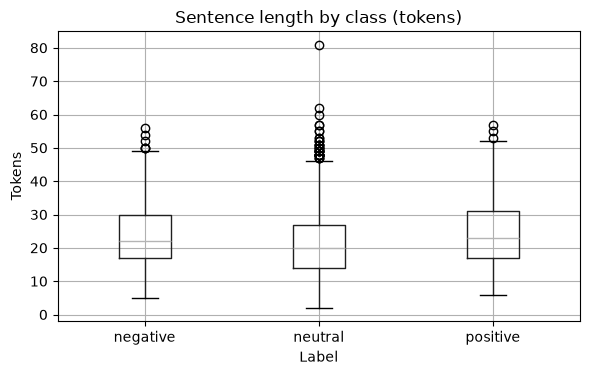


Longest sentence:
 Supported Nokia phones include : N96 , N95-8GB , N95 , N93-N931 , N92 , N85 , N82 , N81 , N80 , N79 , N78 , N77 , N76 , N75 , N73 , N72 , N71 , E90 , E71 , E70 , E66 , E65 , E62 , E61-E61i , E60 , E51 , E50 , Touch Xpress 5800 , 6220 Classic , 6210 Navigator , 6120 Classic , 6110 Navigator , 5700 , 5500 , 5320XM .


In [23]:
## sentence lengths

df["n_tokens"] = df["sentence"].str.split().str.len()

print(df["n_tokens"].describe().round(1))
print()
print("95th percentile:",df["n_tokens"].quantile(0.95))
print("99th percentile:",df["n_tokens"].quantile(0.99))
print()
print("mean length per clss:")
print(df.groupby("label")["n_tokens"].agg(["mean","median","max"]).round(1))

ax=df.boxplot(column="n_tokens", by="label", figsize=(6,4))
plt.suptitle("")
ax.set_title("Sentence length by class (tokens)")
ax.set_xlabel("Label")
ax.set_ylabel("Tokens")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_sentence_length.png",dpi=150)
plt.show()

print("\nLongest sentence:\n",
df.loc[df["n_tokens"].idxmax(), "sentence"])

In [24]:
##most word per class
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

def words(text):
    ##lowercase, keep only alphabetic token (drops numbers and punctuation)
    return [w for w in text.lower().split() if w.isalpha()]

for label in class_order:
    counter = Counter()
    for sentence in df.loc[df["label"] == label,"sentence"]:
        counter.update(w for w in words(sentence) if w not in ENGLISH_STOP_WORDS)
    print(f"\n{label.upper()}: {counter.most_common(15)}")

## which sentiment carring words would a standard stop word list delte?

check = ["up","down","not","no","less","more","above","below","against","without","over","under"]
print("\nRemoved by sklearn's stop-word list:",[w for w in check if w in ENGLISH_STOP_WORDS])



NEGATIVE: [('eur', 298), ('mn', 213), ('profit', 149), ('net', 98), ('operating', 86), ('sales', 85), ('quarter', 74), ('finnish', 74), ('period', 72), ('million', 69), ('year', 65), ('mln', 65), ('loss', 64), ('compared', 60), ('decreased', 58)]

NEUTRAL: [('company', 381), ('eur', 198), ('finland', 157), ('million', 154), ('group', 142), ('said', 142), ('shares', 140), ('business', 137), ('sales', 129), ('finnish', 119), ('new', 119), ('services', 112), ('share', 105), ('net', 94), ('market', 87)]

POSITIVE: [('eur', 420), ('mn', 239), ('net', 186), ('profit', 185), ('sales', 161), ('said', 156), ('finnish', 149), ('million', 143), ('company', 140), ('period', 137), ('year', 125), ('m', 122), ('mln', 115), ('operating', 114), ('quarter', 103)]

Removed by sklearn's stop-word list: ['up', 'down', 'not', 'no', 'less', 'more', 'above', 'below', 'against', 'without', 'over', 'under']


- **Sentence length:** median 21 tokens, 95th pct 42, 99th pct 50, max 81 (a Nokia model list). LSTM max_len = 50.
- **Length is not a class signal:** neutral slightly shorter, heavy overlap; positive ≈ negative.
- **Unit spelling variants:** mn / mln / m / million all mean the same. Normalize in Phase 3.
- **Stop words:** sklearn's list removes up, down, not, no, less, more. Do NOT use the default list.
- **Duplicates:** 5 exact duplicate pairs (all neutral, no conflicts), drop before splitting. 24 near-duplicate template groups. Split must keep each group in one set.